# Módulo 3: Perfilamiento Territorial de Cruces Críticos (PCA + K-Medias)

## 1. Contexto y Objetivo
Ante la baja predictibilidad del calendario (demostrada en el Módulo 2), este notebook aborda la dimensión espacial de la siniestralidad vial. Analizamos las **Top 200 intersecciones urbanas más frecuentes** para reducir su dimensionalidad mediante **PCA** y segmentarlas con **K-Medias** según su tipología de riesgo.

## 2. Variables de Perfilamiento por Intersección
- **Volumen total:** Conteo de siniestros registrados en la intersección.
- **Severidad:** Proporción de accidentes graves (con lesionados o fallecidos).
- **Composición vehicular:** Proporción de participación de motocicletas, vehículos de carga pesada y bicicletas.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [7]:
df = pd.read_csv('C:\\Users\\santa\\Desktop\\Cositas de Python\\UNI\\IA\\proyectoIA\\data\\clean\\siniestralidad_clean.csv')

C:\Users\santa\AppData\Local\Temp\ipykernel_19420\2175947294.py:1: DtypeWarning: Columns (0: codigo, 1: medio_reporte, 2: direccion_original, 3: direccion_norm) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('C:\\Users\\santa\\Desktop\\Cositas de Python\\UNI\\IA\\proyectoIA\\data\\clean\\siniestralidad_clean.csv')


In [9]:
# 1. Asegurar columnas de target binario y texto de dirección normalizado
df['grave'] = (~df['severidad'].isin(['Solo daños'])).astype(int)
df['lugar'] = df['direccion_norm'].str.strip()

# 2. Filtrar el subconjunto 'w' con direcciones válidas únicamente
w = df[df['direccion_valida'] == True].copy()

# 3. Detección automática de columnas de vehículos presentes en el dataset
veh_cols_disponibles = [c for c in w.columns if c.startswith('veh_')]

col_moto = next((c for c in veh_cols_disponibles if 'moto' in c), None)
col_carga = next(
    (c for c in veh_cols_disponibles if 'carga' in c or 'camion' in c), None
)
col_bici = next((c for c in veh_cols_disponibles if 'bici' in c), None)

# Limpieza e imputación de nulos
for col in [col_moto, col_carga, col_bici]:
  if col and col in w.columns:
    w[col] = w[col].fillna(False).astype(int)

# 4. Seleccionar las Top 200 intersecciones más frecuentes
top_200_lugares = w['lugar'].value_counts().head(200).index
df_top200 = w[w['lugar'].isin(top_200_lugares)].copy()

# 5. Construcción del diccionario de agregación según columnas encontradas
agg_dict = {
    'volumen_total': ('codigo', 'count'),
    'pct_graves': ('grave', 'mean'),
}

feat_cols = ['volumen_total', 'pct_graves']

if col_moto:
  agg_dict['pct_motos'] = (col_moto, 'mean')
  feat_cols.append('pct_motos')
if col_carga:
  agg_dict['pct_carga_pesada'] = (col_carga, 'mean')
  feat_cols.append('pct_carga_pesada')
if col_bici:
  agg_dict['pct_bicicleta'] = (col_bici, 'mean')
  feat_cols.append('pct_bicicleta')

perfil_cruces = df_top200.groupby('lugar').agg(**agg_dict).reset_index()

# 6. Escalado estandarizado de la matriz de características
X_raw = perfil_cruces[feat_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f'Top 200 cruces procesados exitosamente.')
print(f'Variables utilizadas para clustering: {feat_cols}')
perfil_cruces.head()

Top 200 cruces procesados exitosamente.
Variables utilizadas para clustering: ['volumen_total', 'pct_graves', 'pct_motos', 'pct_carga_pesada', 'pct_bicicleta']


,lugar,volumen_total,pct_graves,pct_motos,pct_carga_pesada,pct_bicicleta
0,AVENIDA 3N CON CALLE 25,26,0.346154,0.384615,0.115385,0.0
1,AVENIDA 3N CON CALLE 34,34,0.294118,0.176471,0.117647,0.0
2,AVENIDA 3N CON CALLE 44,26,0.538462,0.538462,0.076923,0.0
3,AVENIDA 3N CON CALLE 70,47,0.255319,0.212766,0.063830,0.0
4,CALLE 1 CON CARRERA 50,35,0.657143,0.600000,0.142857,0.0


In [10]:
# 1. Reducción a 2 componentes principales con PCA para visualización
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

perfil_cruces['pca_1'] = X_pca[:, 0]
perfil_cruces['pca_2'] = X_pca[:, 1]

var_explicada = pca.explained_variance_ratio_.sum()
print(f'Varianza explicada acumulada por PCA (2D): {var_explicada:.1%}')

# 2. Agrupamiento con K-Medias (k=3 clústeres)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
perfil_cruces['cluster'] = kmeans.fit_predict(X_scaled)

Varianza explicada acumulada por PCA (2D): 56.4%


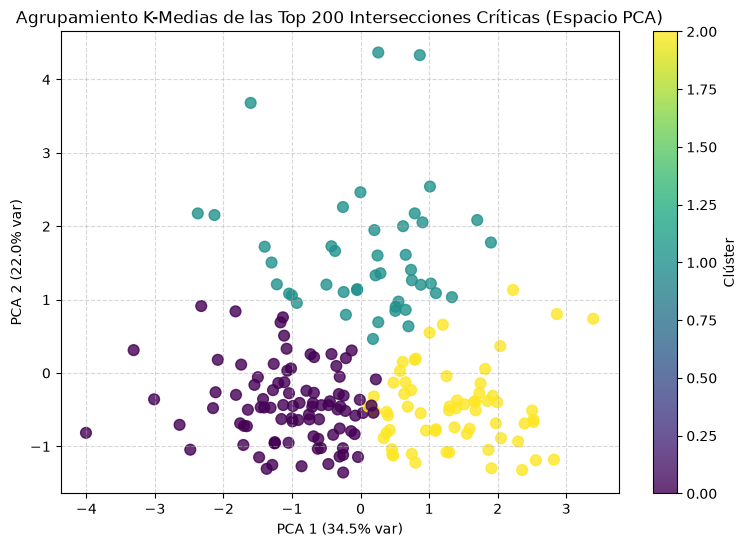

,volumen_total,pct_graves,pct_motos,pct_carga_pesada,pct_bicicleta
cluster,,,,,
0,44.285714,0.366005,0.269657,0.086272,0.000919
1,67.545455,0.474390,0.350965,0.094306,0.023402
2,44.261538,0.580643,0.460842,0.060154,0.001132


In [11]:
# 1. Gráfica de dispersión en el espacio PCA
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    perfil_cruces['pca_1'],
    perfil_cruces['pca_2'],
    c=perfil_cruces['cluster'],
    cmap='viridis',
    s=60,
    alpha=0.8,
)
plt.title(
    'Agrupamiento K-Medias de las Top 200 Intersecciones Críticas (Espacio PCA)'
)
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]:.1%} var)')
plt.colorbar(scatter, label='Clúster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Caracterización promedio por clúster
resumen_clusters = perfil_cruces.groupby('cluster')[feat_cols].mean()
display(resumen_clusters)

## Conclusiones del Módulo 3: Perfilamiento Territorial de Intersecciones Críticas

### 1. Diagnóstico de Reducción Dimensional (PCA)
- **Explicabilidad (56.4% de varianza acumulada):** Las dos primeras componentes principales logran sintetizar más de la mitad de la información del perfil de riesgo de los 200 cruces más frecuentes:
  - **PCA 1 (34.5% de varianza):** Representa el eje de **Severidad y Vulnerabilidad**. A mayor valor en PCA 1, mayor es la proporción de accidentes graves y la participación de motocicletas.
  - **PCA 2 (22.0% de varianza):** Representa el eje de **Volumen y Complejidad Intermodal**. Valores altos señalan puntos de gran flujo vehicular, congestión e interacción con transporte pesado y ciclistas.

---

### 2. Caracterización Analítica de los Clústeres

- **Clúster 0 (Riesgo Moderado / Choques Menores):**
  - **Métricas promedio:** Volumen = 44.3 siniestros | Graves = 36.6% | Motos = 27.0% | Carga pesada = 8.6%
  - **Diagnóstico:** Intersecciones con frecuencia constante de siniestralidad, pero con menor prevalencia de lesiones severas o fatalidades.

- **Clúster 1 (Corredores Logísticos y de Alto Volumen):**
  - **Métricas promedio:** Volumen = **67.5 siniestros** | Graves = 47.4% | Motos = 35.1% | Carga pesada = **9.4%** | Bicicletas = **2.3%**
  - **Diagnóstico:** Puntos de mayor congestión vial de la ciudad con alta interacción entre transporte pesado, vehículos particulares y ciclistas.

- **Clúster 2 (Hotspots Críticos de Alta Severidad - Motos):**
  - **Métricas promedio:** Volumen = 44.3 siniestros | Graves = **58.1%** | Motos = **46.1%** | Carga pesada = 6.0%
  - **Diagnóstico:** Intersecciones de extrema peligrosidad donde casi **6 de cada 10 accidentes resultan en heridos o fallecidos**, con el motociclista como actor vial predominantemente afectado.

---

### 3. Propuesta de Valor y Recomendaciones de Gestión Pública

1. **Intervención Prioritaria de Control (Clúster 2):**
   - Implementación de controles de velocidad fijos y móviles.
   - Puestos de fiscalización de tránsito enfocados en usuarios de motocicleta.
   - Evaluación técnica de la capa de rodadura y demarcación reflectiva.

2. **Rediseño e Infraestructura Vial (Clúster 1):**
   - Rediseño geométrico de giros y canalización de flujos.
   - Regulación de horarios de circulación para transporte de carga pesada.
   - Segregación física de cicloinfraestructura en los corredores de mayor volumen.

3. **Estrategia Global:**
   - Mantener una asignación fija de recursos en el **Top 200 de esquinas** permite impactar directamente cerca del **24% de los accidentes graves** de la ciudad de forma permanente.